# Setup

In [164]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [165]:
# Load the data
df = pd.read_csv('Turing_Test2026-08-05_15_46_24.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 23 columns):
 #   Column                                                                 Non-Null Count  Dtype  
---  ------                                                                 --------------  -----  
 0   Submission Date                                                        24 non-null     object 
 1   Randomization                                                          24 non-null     float64
 2   Completion Time                                                        24 non-null     object 
 3   P1. Which audio clip was synthesized from transcribed human speech?    13 non-null     object 
 4   P2. Which audio clip was synthesized from transcribed human speech?    13 non-null     object 
 5   P3. Which audio clip was synthesized from transcribed human speech?    13 non-null     object 
 6   P4. Which audio clip was synthesized from transcribed human speech?    13 non-null     objec

In [166]:
# Load answer key and shuffle order
mapping = pd.read_excel('turing_mapping.xlsx')
answer_key = mapping[['P_id', 'human_clip']]
answer_key

,P_id,human_clip
0,P1,A
1,P2,B
2,P3,B
3,P4,A
4,P5,A
5,P6,B
6,P7,A


In [167]:
# Pair random shuffling order corresponding to sample number
shuffle_order = mapping[['P_id', 'sample_num']]
shuffle_order

,P_id,sample_num
0,P1,1
1,P2,9
2,P3,5
3,P4,2
4,P5,8
5,P6,7
6,P7,3


# Preprocessing

In [168]:
df.head()

,Submission Date,Randomization,Completion Time,P1. Which audio clip was synthesized from transcribed human speech?,P2. Which audio clip was synthesized from transcribed human speech?,P3. Which audio clip was synthesized from transcribed human speech?,P4. Which audio clip was synthesized from transcribed human speech?,P5. Which audio clip was synthesized from transcribed human speech?,P6. Which audio clip was synthesized from transcribed human speech?,P7. Which audio clip was synthesized from transcribed human speech?,...,P4. Which audio clip was synthesized from transcribed human speech?.1,P5. Which audio clip was synthesized from transcribed human speech?.1,P6. Which audio clip was synthesized from transcribed human speech?.1,P7. Which audio clip was synthesized from transcribed human speech?.1,Gender,Age,What do you do for a living?,How would you rate your English proficiency level?,What is/are your native language/s?,What type of audio device did you use to listen to the clips?
0,"Aug 5, 2026",0.63,Time taken to fill form: 00:01:32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Audio Clip B,Audio Clip A,Audio Clip A,Audio Clip B,Male,18,Student,Beginner (I know and can speak only basic word...,Hebrew\nRussian,Headphones / Earbuds
1,"Aug 5, 2026",0.25,Time taken to fill form: 00:05:05,Audio Clip B,Audio Clip A,Audio Clip B,Audio Clip A,Audio Clip A,Audio Clip A,Audio Clip A,...,NaN,NaN,NaN,NaN,Female,22,Technological Role,Fluent (I can speak freely in English and unde...,Hebrew,Monitor speakers / External desktop speakers /...
2,"Aug 5, 2026",0.55,Time taken to fill form: 00:04:43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Audio Clip A,Audio Clip B,Audio Clip A,Audio Clip A,Male,22,Student,Fluent (I can speak freely in English and unde...,Hebrew\nRussian,Headphones / Earbuds
3,"Aug 5, 2026",0.95,Time taken to fill form: 00:02:46,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Audio Clip A,Audio Clip A,Audio Clip B,Audio Clip A,Male,23,Academic / Researcher / Educator,Fluent (I can speak freely in English and unde...,Hebrew\nEnglish,Monitor speakers / External desktop speakers /...
4,"Aug 5, 2026",0.27,Time taken to fill form: 00:02:29,Audio Clip A,Audio Clip B,Audio Clip A,Audio Clip B,Audio Clip B,Audio Clip B,Audio Clip B,...,NaN,NaN,NaN,NaN,Male,25,Technological Role\nAcademic / Researcher / Ed...,Native or Bilingual,English\nArabic,Monitor speakers / External desktop speakers /...


In [169]:
# Participants with a random value greater than 0.5 are assigned to the Gemma condition, while those with a random value less than or equal to 0.5 are assigned to the Llama condition.

df['Condition'] = df['Randomization'].apply(lambda x: 'Gemma' if x > 0.5 else 'Llama')
df.drop(['Randomization'], axis=1, inplace=True)

In [170]:
df['Completion Time (sec)'] = pd.to_timedelta(df['Completion Time'].str[-8:]).dt.total_seconds()
df.drop(['Completion Time'], axis=1, inplace=True)

In [171]:
# Merge pair response data
base_cols = [
    f"P{i}. Which audio clip was synthesized from transcribed human speech?"
    for i in range(1, 8)
]
dot_cols = [f"{col}.1" for col in base_cols]

# Combine the condition A columns with the condition B (.1) columns
merged_responses = df[base_cols].combine_first(
    df[dot_cols].rename(columns=dict(zip(dot_cols, base_cols)))
)

# Overwrite the original columns with the merged values
df[base_cols] = merged_responses

# Drop the extra .1 columns
df.drop(columns=dot_cols, inplace=True)

In [172]:
# Simplify the pair response columns to just 'A' or 'B'
df[base_cols] = df[base_cols].map(lambda x: x[-1])

In [173]:
df['Total Correct'] = df[base_cols].eq(answer_key['human_clip'].values).sum(axis=1)
df['Accuracy'] = df['Total Correct'] / len(base_cols)

In [174]:
cols_to_rename = {
    'What do you do for a living?' : 'Occupation',
    'How would you rate your English proficiency level?' : 'English Proficiency',
    'What is/are your native language/s?' : 'Native Languages',
    'What type of audio device did you use to listen to the clips?' : 'Audio Device'
}

df = df.rename(columns=cols_to_rename)
df

,Submission Date,P1. Which audio clip was synthesized from transcribed human speech?,P2. Which audio clip was synthesized from transcribed human speech?,P3. Which audio clip was synthesized from transcribed human speech?,P4. Which audio clip was synthesized from transcribed human speech?,P5. Which audio clip was synthesized from transcribed human speech?,P6. Which audio clip was synthesized from transcribed human speech?,P7. Which audio clip was synthesized from transcribed human speech?,Gender,Age,Occupation,English Proficiency,Native Languages,Audio Device,Condition,Completion Time (sec),Total Correct,Accuracy
0,"Aug 5, 2026",A,B,B,B,A,A,B,Male,18,Student,Beginner (I know and can speak only basic word...,Hebrew\nRussian,Headphones / Earbuds,Gemma,92.0,4,0.571429
1,"Aug 5, 2026",B,A,B,A,A,A,A,Female,22,Technological Role,Fluent (I can speak freely in English and unde...,Hebrew,Monitor speakers / External desktop speakers /...,Llama,305.0,4,0.571429
2,"Aug 5, 2026",B,A,B,A,B,A,A,Male,22,Student,Fluent (I can speak freely in English and unde...,Hebrew\nRussian,Headphones / Earbuds,Gemma,283.0,3,0.428571
3,"Aug 5, 2026",A,A,A,A,A,B,A,Male,23,Academic / Researcher / Educator,Fluent (I can speak freely in English and unde...,Hebrew\nEnglish,Monitor speakers / External desktop speakers /...,Gemma,166.0,5,0.714286
4,"Aug 5, 2026",A,B,A,B,B,B,B,Male,25,Technological Role\nAcademic / Researcher / Ed...,Native or Bilingual,English\nArabic,Monitor speakers / External desktop speakers /...,Llama,149.0,3,0.428571
5,"Aug 5, 2026",B,B,B,B,B,B,A,Female,22,Student,Fluent (I can speak freely in English and unde...,Portuguese,Headphones / Earbuds,Gemma,121.0,4,0.571429
6,"Aug 5, 2026",B,B,A,A,A,B,B,Male,29,Student\nAcademic / Researcher / Educator,Fluent (I can speak freely in English and unde...,Hebrew\nEnglish\nRussian\nItalian,Phone speakers,Llama,279.0,4,0.571429
7,"Aug 5, 2026",B,B,B,A,A,A,A,Male,24,Student,Intermediate (I can handle most everyday conve...,Arabic,Monitor speakers / External desktop speakers /...,Gemma,214.0,5,0.714286
8,"Aug 5, 2026",A,A,B,A,B,A,A,Female,23,Academic / Researcher / Educator,Native or Bilingual,English\nRussian,Monitor speakers / External desktop speakers /...,Llama,172.0,4,0.571429
9,"Aug 5, 2026",B,B,A,B,B,A,B,Male,24,Academic / Researcher / Educator,Fluent (I can speak freely in English and unde...,Hebrew,Headphones / Earbuds,Llama,192.0,1,0.142857


In [175]:
# Split multi-answer columns responses into a list of the values using \n

multi_answer_cols = ['Occupation', 'Native Languages']

for col in multi_answer_cols:
    df[col] = df[col].str.split('\n')

df

,Submission Date,P1. Which audio clip was synthesized from transcribed human speech?,P2. Which audio clip was synthesized from transcribed human speech?,P3. Which audio clip was synthesized from transcribed human speech?,P4. Which audio clip was synthesized from transcribed human speech?,P5. Which audio clip was synthesized from transcribed human speech?,P6. Which audio clip was synthesized from transcribed human speech?,P7. Which audio clip was synthesized from transcribed human speech?,Gender,Age,Occupation,English Proficiency,Native Languages,Audio Device,Condition,Completion Time (sec),Total Correct,Accuracy
0,"Aug 5, 2026",A,B,B,B,A,A,B,Male,18,[Student],Beginner (I know and can speak only basic word...,"[Hebrew, Russian]",Headphones / Earbuds,Gemma,92.0,4,0.571429
1,"Aug 5, 2026",B,A,B,A,A,A,A,Female,22,[Technological Role],Fluent (I can speak freely in English and unde...,[Hebrew],Monitor speakers / External desktop speakers /...,Llama,305.0,4,0.571429
2,"Aug 5, 2026",B,A,B,A,B,A,A,Male,22,[Student],Fluent (I can speak freely in English and unde...,"[Hebrew, Russian]",Headphones / Earbuds,Gemma,283.0,3,0.428571
3,"Aug 5, 2026",A,A,A,A,A,B,A,Male,23,[Academic / Researcher / Educator],Fluent (I can speak freely in English and unde...,"[Hebrew, English]",Monitor speakers / External desktop speakers /...,Gemma,166.0,5,0.714286
4,"Aug 5, 2026",A,B,A,B,B,B,B,Male,25,"[Technological Role, Academic / Researcher / E...",Native or Bilingual,"[English, Arabic]",Monitor speakers / External desktop speakers /...,Llama,149.0,3,0.428571
5,"Aug 5, 2026",B,B,B,B,B,B,A,Female,22,[Student],Fluent (I can speak freely in English and unde...,[Portuguese],Headphones / Earbuds,Gemma,121.0,4,0.571429
6,"Aug 5, 2026",B,B,A,A,A,B,B,Male,29,"[Student, Academic / Researcher / Educator]",Fluent (I can speak freely in English and unde...,"[Hebrew, English, Russian, Italian]",Phone speakers,Llama,279.0,4,0.571429
7,"Aug 5, 2026",B,B,B,A,A,A,A,Male,24,[Student],Intermediate (I can handle most everyday conve...,[Arabic],Monitor speakers / External desktop speakers /...,Gemma,214.0,5,0.714286
8,"Aug 5, 2026",A,A,B,A,B,A,A,Female,23,[Academic / Researcher / Educator],Native or Bilingual,"[English, Russian]",Monitor speakers / External desktop speakers /...,Llama,172.0,4,0.571429
9,"Aug 5, 2026",B,B,A,B,B,A,B,Male,24,[Academic / Researcher / Educator],Fluent (I can speak freely in English and unde...,[Hebrew],Headphones / Earbuds,Llama,192.0,1,0.142857


In [176]:
# Convert 'Phone speakers' value to Monitor speakers in the 'Audio Device' column

df['Audio Device'] = df['Audio Device'].replace('Phone speakers', 'Monitor speakers / External desktop speakers / Mobile phone speakers')

In [177]:
df['Completion Time (min)'] = df['Completion Time (sec)'] / 60

# Sample EDA

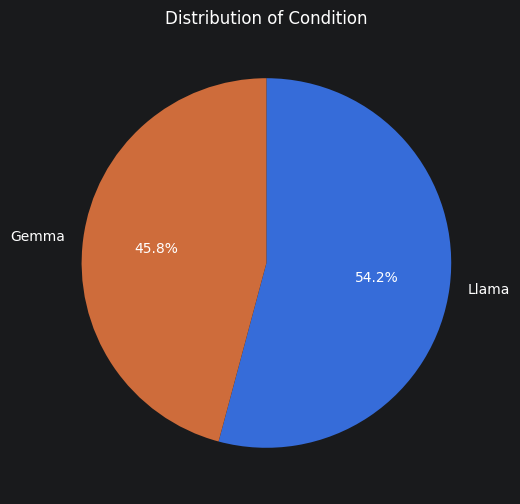

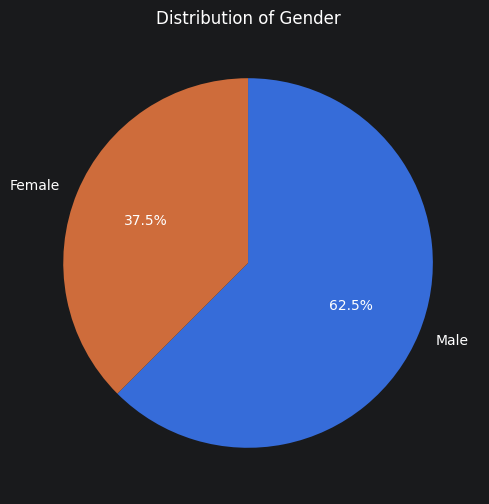

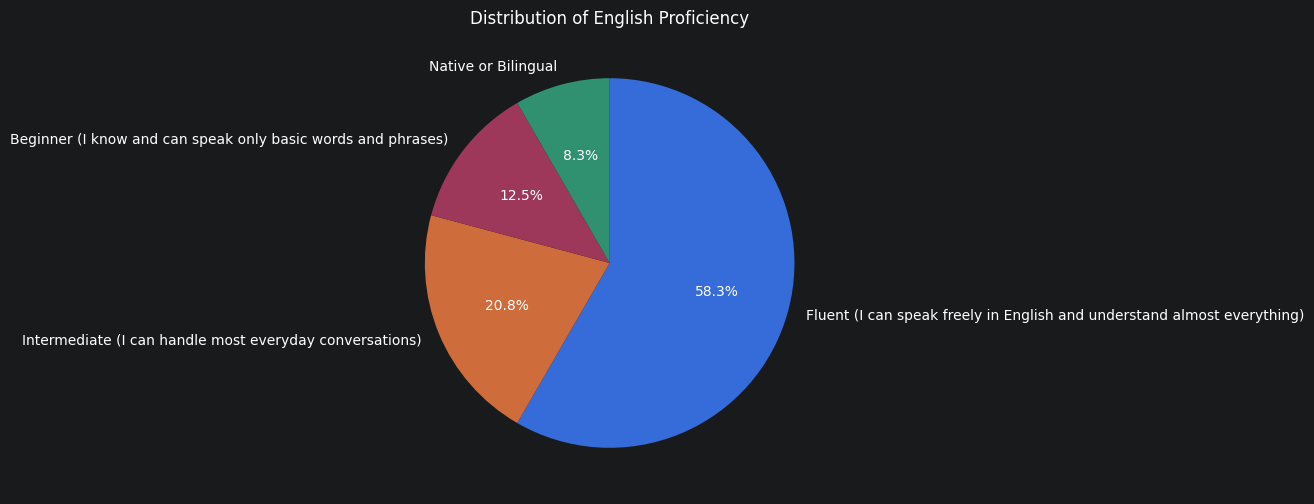

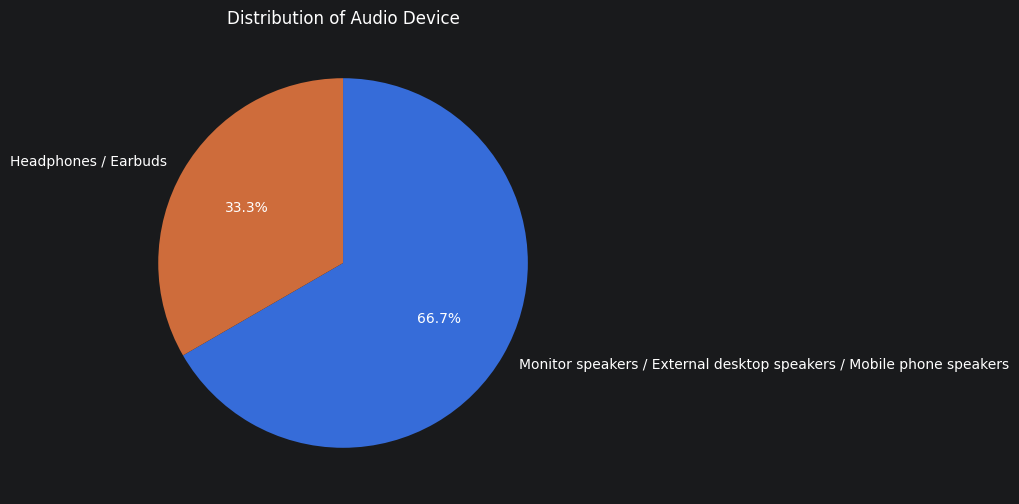

In [178]:
categorical_cols = ['Condition', 'Gender', 'English Proficiency', 'Audio Device']

for col in categorical_cols:
    # plot a pie chart
    plt.figure(figsize=(6, 6))
    df[col].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, counterclock=False)
    plt.title(f'Distribution of {col}')
    plt.ylabel('')
    plt.show()

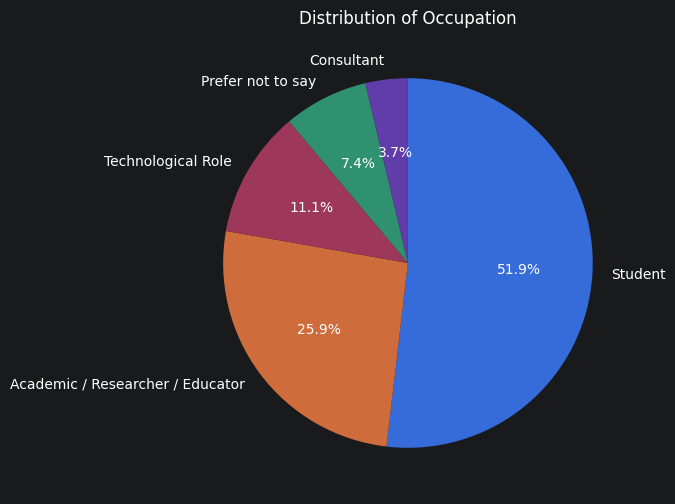

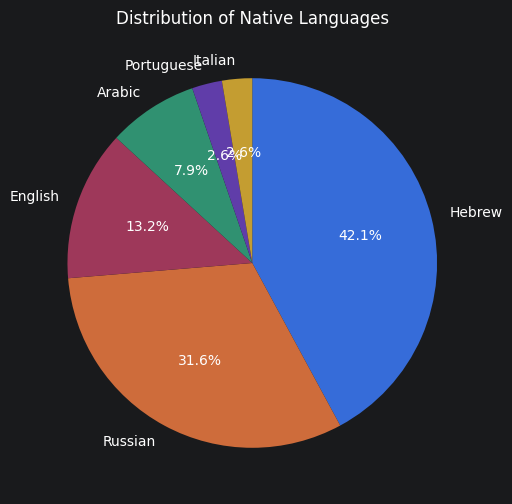

In [179]:
# Plot pie charts for multi-answer columns, but explode the lists into separate rows first

for col in multi_answer_cols:
    # Explode the lists into separate rows
    exploded_df = df.explode(col)

    # Plot a pie chart
    plt.figure(figsize=(6, 6))
    exploded_df[col].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, counterclock=False)
    plt.title(f'Distribution of {col}')
    plt.ylabel('')
    plt.show()

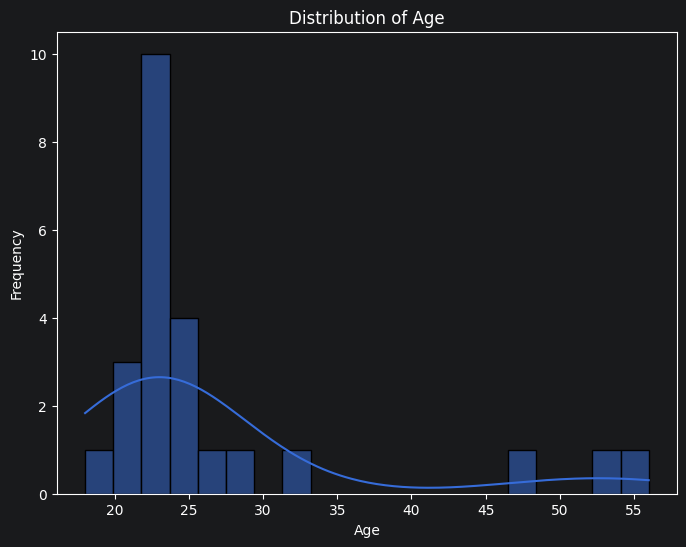

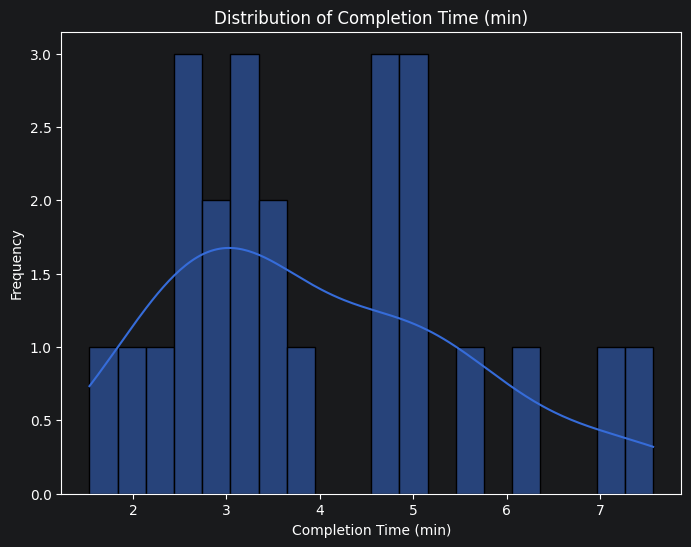

In [180]:
hist_cols = ['Age', 'Completion Time (min)']

for col in hist_cols:
    plt.figure(figsize=(8, 6))
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

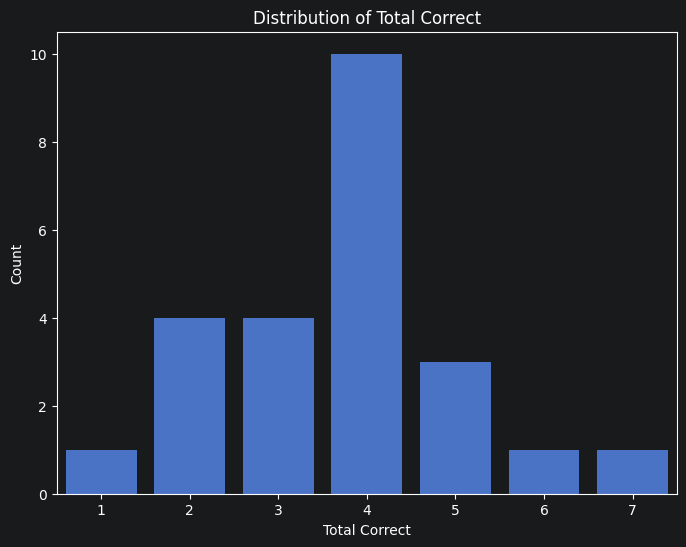

In [181]:
barplot_cols = ['Total Correct']

for col in barplot_cols:
    plt.figure(figsize=(8, 6))
    sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

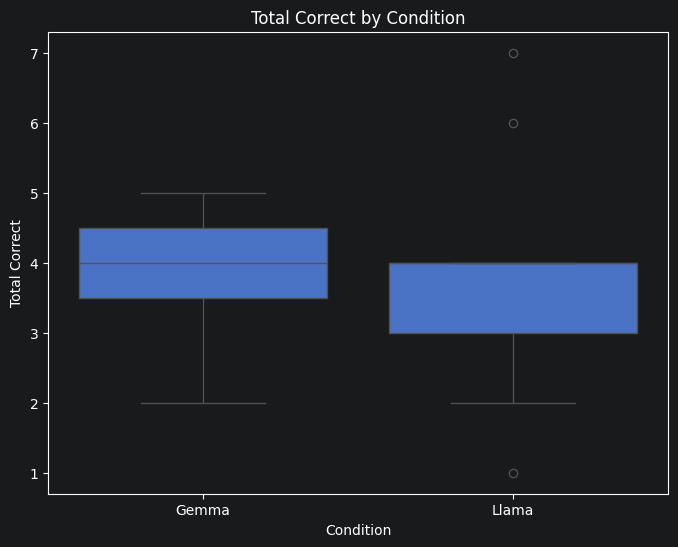

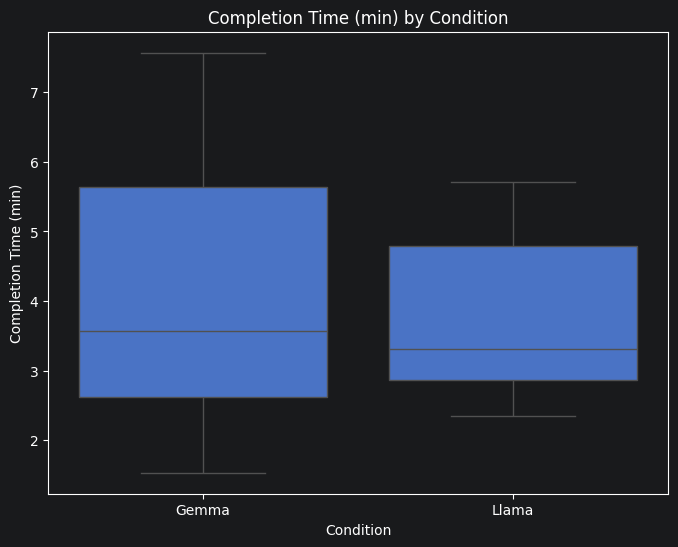

In [182]:
vars_by_cond = ['Total Correct', 'Completion Time (min)']

# Create boxplots for each variable by condition
for var in vars_by_cond:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='Condition', y=var, data=df)
    plt.title(f'{var} by Condition')
    plt.xlabel('Condition')
    plt.ylabel(var)
    plt.show()

# Statistical Tests

In [183]:
# Perform a t-test and a mann-whitney test to compare the means of Total Correct between the two conditions
from scipy.stats import ttest_ind, mannwhitneyu

for var in vars_by_cond:
    group1 = df[df['Condition'] == 'Gemma'][var]
    group2 = df[df['Condition'] == 'Llama'][var]

    # Perform t-test
    t_stat, p_value = ttest_ind(group1, group2)
    print(f"T-test for {var}:")
    print(f"t-statistic: {t_stat:.4f}, p-value: {p_value:.4f}")
    print()

    # Perform Mann-Whitney U test
    u_stat, p_value = mannwhitneyu(group1, group2)
    print(f"Mann-Whitney U test for {var}:")
    print(f"U-statistic: {u_stat:.4f}, p-value: {p_value:.4f}")
    print()


T-test for Total Correct:
t-statistic: 0.3553, p-value: 0.7258

Mann-Whitney U test for Total Correct:
U-statistic: 84.0000, p-value: 0.4680

T-test for Completion Time (min):
t-statistic: 0.6741, p-value: 0.5073

Mann-Whitney U test for Completion Time (min):
U-statistic: 78.5000, p-value: 0.7064



In [184]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Create a unique Participant ID (needed for clustering repeated measures)
df['Participant_ID'] = df.index

# 2. Melt the dataframe from wide to long format
long_df = df.melt(
    id_vars=['Participant_ID', 'Condition'],
    value_vars=base_cols,
    var_name='Question_Text',
    value_name='Response'
)

# 3. Extract the P_id (e.g., 'P1') to merge with the answer key
long_df['P_id'] = long_df['Question_Text'].apply(lambda x: x.split('.')[0])
long_df = long_df.merge(answer_key, on='P_id')

# 4. Create the binary outcome column (1 = Correct, 0 = Incorrect)
long_df['Is_Correct'] = (long_df['Response'] == long_df['human_clip']).astype(int)

# 5. Fit the GEE Model
# We model 'Is_Correct' against 'Condition', clustered by 'Participant_ID', using a Binomial family.
model = smf.gee(
    "Is_Correct ~ C(Condition)",
    groups=long_df['Participant_ID'],
    data=long_df,
    family=sm.families.Binomial()
)
gee_results = model.fit()

# 6. Display the results
print(gee_results.summary())

                               GEE Regression Results                              
Dep. Variable:                  Is_Correct   No. Observations:                  168
Model:                                 GEE   No. clusters:                       24
Method:                        Generalized   Min. cluster size:                   7
                      Estimating Equations   Max. cluster size:                   7
Family:                           Binomial   Mean cluster size:                 7.0
Dependence structure:         Independence   Num. iterations:                     2
Date:                     Wed, 05 Aug 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         22:48:40
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.1823      0.179      1.020      0.30